<a href="https://colab.research.google.com/github/murtaza-waris/python_ai_ml/blob/main/CNNs_model_on_Kaggle_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import kagglehub
import os

dataset_path = kagglehub.dataset_download("anthonytherrien/image-classification-64-classes-animal")

print("Downloaded to:", dataset_path)
print("Contents:", os.listdir(dataset_path))


100%|██████████| 5.71G/5.71G [05:15<00:00, 19.4MB/s]

Extracting files...


Downloaded to: /root/.cache/kagglehub/datasets/anthonytherrien/image-classification-64-classes-animal/versions/1
Contents: ['image']


In [2]:
data_dir = os.path.join(dataset_path, "image")
print(data_dir)

/root/.cache/kagglehub/datasets/anthonytherrien/image-classification-64-classes-animal/versions/1/image


In [3]:
import tensorflow as tf

IMG_SIZE = (128, 128)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=32,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
 )

validate_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=32,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

Found 14377 files belonging to 64 classes.
Using 11502 files for training.
Found 14377 files belonging to 64 classes.
Using 2875 files for validation.


In [4]:
class_names = train_ds.class_names
num_classes = len(class_names)
print(class_names)
print(num_classes)

['antelope', 'bear', 'beaver', 'bee', 'bison', 'blackbird', 'buffalo', 'butterfly', 'camel', 'cat', 'cheetah', 'chimpanzee', 'chinchilla', 'cow', 'crab', 'crocodile', 'deer', 'dog', 'dolphin', 'donkey', 'duck', 'eagle', 'elephant', 'falcon', 'ferret', 'flamingo', 'fox', 'frog', 'giraffe', 'goat', 'goose', 'gorilla', 'grasshopper', 'hawk', 'hedgehog', 'hippopotamus', 'hyena', 'iguana', 'jaguar', 'kangaroo', 'koala', 'lemur', 'leopard', 'lizard', 'lynx', 'mole', 'mongoose', 'ostrich', 'otter', 'owl', 'panda', 'peacock', 'penguin', 'porcupine', 'raccoon', 'seal', 'sheep', 'snail', 'snake', 'spider', 'squid', 'walrus', 'whale', 'wolf']
64


In [5]:
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
validate_ds   = validate_ds.prefetch(buffer_size=AUTOTUNE)

In [6]:
from tensorflow.keras import layers,models

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.1)
])

In [7]:
model = models.Sequential([
    layers.Input(shape=(128,128,3)),
    data_augmentation,
    layers.Rescaling(1./255),

    #Block 1
    layers.Conv2D(32,3,padding="same",activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2,2),

    #Block 2
    layers.Conv2D(64,3,padding="same",activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2,2),

    #Block 3
    layers.Conv2D(128,3,padding="same",activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2,2),

    #Block 4
    layers.Conv2D(256,3,padding="same",activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2,2),

    #Classification Head
    layers.Flatten(),
    layers.Dense(256,activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(num_classes,activation="softmax")

 ])

In [8]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     4,194,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │        16,448 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,601,344 (17.55 MB)

 Trainable params: 4,600,384 (17.55 MB)

 Non-trainable params: 960 (3.75 KB)

In [9]:
#Training with Smart Callbacks

from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Re-compile model with the correct spelling of sparse_categorical_crossentropy
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks=[
    EarlyStopping(monitor="val_loss",patience=6,restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss",factor=0.5,patience=3,verbose=1)
    ]

history = model.fit(
    train_ds,
    validation_data=validate_ds,
    epochs=35,
    callbacks=callbacks
 )

Epoch 1/35
360/360 ━━━━━━━━━━━━━━━━━━━━ 143s 370ms/step - accuracy: 0.0676 - loss: 4.1653 - val_accuracy: 0.0306 - val_loss: 4.0593 - learning_rate: 0.0010
Epoch 2/35
360/360 ━━━━━━━━━━━━━━━━━━━━ 116s 319ms/step - accuracy: 0.0722 - loss: 3.9479 - val_accuracy: 0.0946 - val_loss: 3.8362 - learning_rate: 0.0010
Epoch 3/35
360/360 ━━━━━━━━━━━━━━━━━━━━ 105s 293ms/step - accuracy: 0.0729 - loss: 3.8714 - val_accuracy: 0.0522 - val_loss: 3.9202 - learning_rate: 0.0010
Epoch 4/35
360/360 ━━━━━━━━━━━━━━━━━━━━ 126s 351ms/step - accuracy: 0.0877 - loss: 3.7103 - val_accuracy: 0.0609 - val_loss: 4.0398 - learning_rate: 0.0010
Epoch 5/35
360/360 ━━━━━━━━━━━━━━━━━━━━ 0s 245ms/step - accuracy: 0.0946 - loss: 3.6558
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
360/360 ━━━━━━━━━━━━━━━━━━━━ 125s 303ms/step - accuracy: 0.0982 - loss: 3.5876 - val_accuracy: 0.1016 - val_loss: 3.9033 - learning_rate: 0.0010
Epoch 6/35
360/360 ━━━━━━━━━━━━━━━━━━━━ 125s 347ms/step - accuracy:

In [10]:
model.save("animal_classification_model.keras")

In [11]:
model.evaluate(validate_ds)

90/90 ━━━━━━━━━━━━━━━━━━━━ 20s 217ms/step - accuracy: 0.8351 - loss: 0.5621


[0.5621337294578552, 0.8351304531097412]

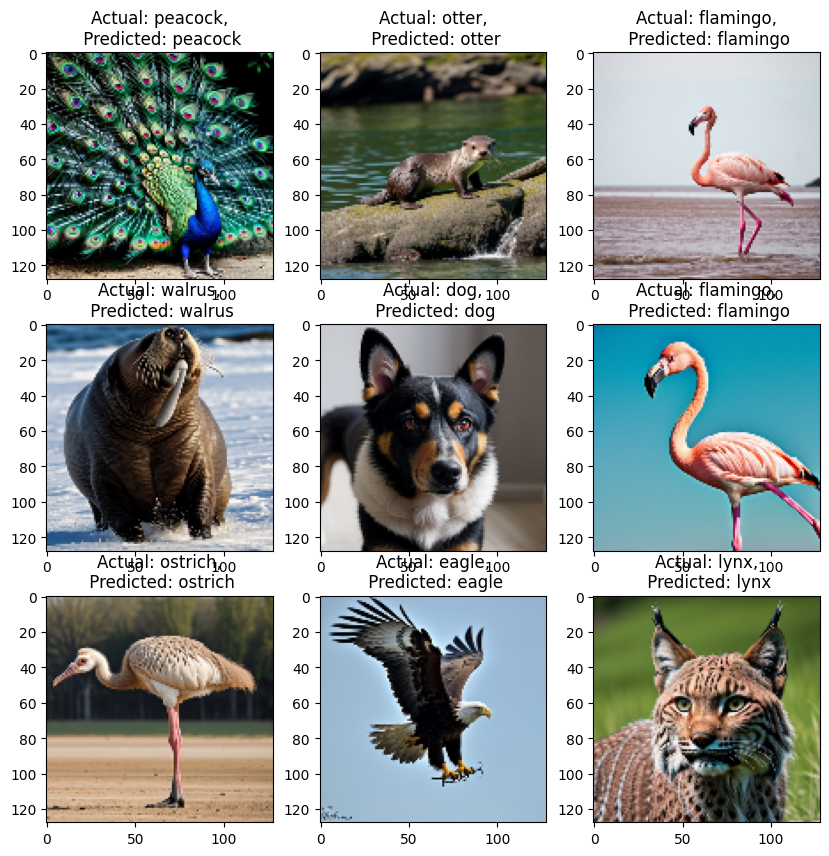

In [12]:
# Test Predictions On Validation Set
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))
for images, labels in val_ds.take(1):
    preds = model.predict(images, verbose=0)
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))

        pred_idx = np.argmax(preds[i])
        conf = np.max(preds[i]) * 100
        actual_name = class_names[labels[i]]
        pred_name = class_names[pred_idx]

        color = 'green' if pred_idx == labels[i] else 'red'
        plt.title(f"True: {actual_name}\nPred: {pred_name} ({conf:.0f}%)", color=color, fontsize=9)
        plt.axis("off")

plt.tight_layout()
plt.show()